# Modelo de predicción: PM2.5 del día siguiente

**Problema.** Predecir, para cada ciudad capital, el PM2.5 (µg/m³) del día siguiente a partir de lo que se sabe hoy.
**Por qué sirve.** Avisar con un día de anticipación qué ciudades superarán la guía diaria de la OMS (15 µg/m³) permite una alerta temprana
(ODS 11.6). Es un caso operativo: cada día llegan datos nuevos y el modelo se aplica a cada ciudad.

**De dónde salen los datos.** De la vista `dw.v_prediction_features`, construida sobre el modelo dimensional ya validado. Combina las tres fuentes:
lecturas de clima y aire (CSV y API), indicadores del país (base de datos de emisiones) y el PM2.5 anual del país (tabla web).

**Contenido**

1. Dataset de predicción
2. Objetivo y línea base
3. División por fecha y ausencia de fuga de datos
4. Preprocesamiento y modelo
5. Evaluación
6. Qué variables pesan
7. Limitaciones
8. Artefactos serializados

In [1]:
import sys

sys.path.append("..")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance

from src.ml_contract import FEATURES, FEATURES_CATEGORICAS, FEATURES_NUMERICAS, TARGET
from src.train_model import cargar_dataset, construir_pipeline, dividir_por_fecha, metricas
from utils.config_loader import load_config, resolve

sns.set_theme(style="whitegrid")
CFG = load_config()
UMBRAL = CFG["quality"]["who_pm25_24h"]
MARGEN = CFG["ml"]["alert_threshold"]

## 1. Dataset de predicción
Una fila por ciudad y día. Las variables de entrada solo usan información conocida ese día o anterior; el objetivo es el PM2.5 del día siguiente.

In [2]:
df = cargar_dataset()
print(f"filas: {len(df):,} | ciudades: {df['location_key'].nunique()} | del {df['feature_date'].min().date()} al {df['feature_date'].max().date()}")
print(f"filas con objetivo conocido (entrenables): {df[TARGET].notna().sum():,}")
print(f"filas sin objetivo (último día de cada ciudad, las que se publican en Kafka): {df[TARGET].isna().sum():,}")
df[["location_name", "feature_date", "pm2_5", "pm25_lag1", "pm25_lag7", "pm25_mean_7d", "temperature_celsius", "co2_per_capita", TARGET]].head(5)

filas: 181,944 | ciudades: 260 | del 2024-05-16 al 2026-11-18
filas con objetivo conocido (entrenables): 180,005
filas sin objetivo (último día de cada ciudad, las que se publican en Kafka): 1,939


,location_name,feature_date,pm2_5,pm25_lag1,pm25_lag7,pm25_mean_7d,temperature_celsius,co2_per_capita,target_pm25_next_day
0,Kabul,2024-05-16,9.4,NaN,NaN,NaN,22.0,0.254,8.3
1,Kabul,2024-05-17,8.3,9.4,NaN,9.40,15.0,0.254,7.5
2,Kabul,2024-05-18,7.5,8.3,NaN,8.85,19.5,0.254,4.8
3,Kabul,2024-05-19,4.8,7.5,NaN,8.40,16.9,0.254,5.8
4,Kabul,2024-05-20,5.8,4.8,NaN,7.50,14.1,0.254,10.2


In [3]:
nulos = (df[FEATURES].isna().mean() * 100).round(1).sort_values(ascending=False)
nulos[nulos > 0]

gdp_per_capita       16.2
energy_per_capita     3.7
pm25_lag7             2.1
co2_per_capita        1.5
pm25_lag3             1.5
pm25_lag2             1.3
delta_wind            1.1
delta_pressure        1.1
pm25_lag1             1.1
delta_temp            1.1
pm25_std_7d           0.4
pm25_mean_3d          0.3
pm25_mean_30d         0.2
pm25_mean_7d          0.2
dtype: float64

**Valores faltantes.** Los rezagos son nulos en los primeros días de cada ciudad, y los indicadores del país faltan en pocos países (por ejemplo, Kosovo no tiene ISO en OWID).
No se imputan con un promedio inventado: el modelo de árboles usado maneja los nulos de forma nativa y aprende qué hacer con ellos.

## 2. Objetivo y línea base
Si el aire de mañana se parece al de hoy, una regla trivial ("mañana = hoy") ya es una buena predicción. **El modelo solo tiene sentido si la mejora.**

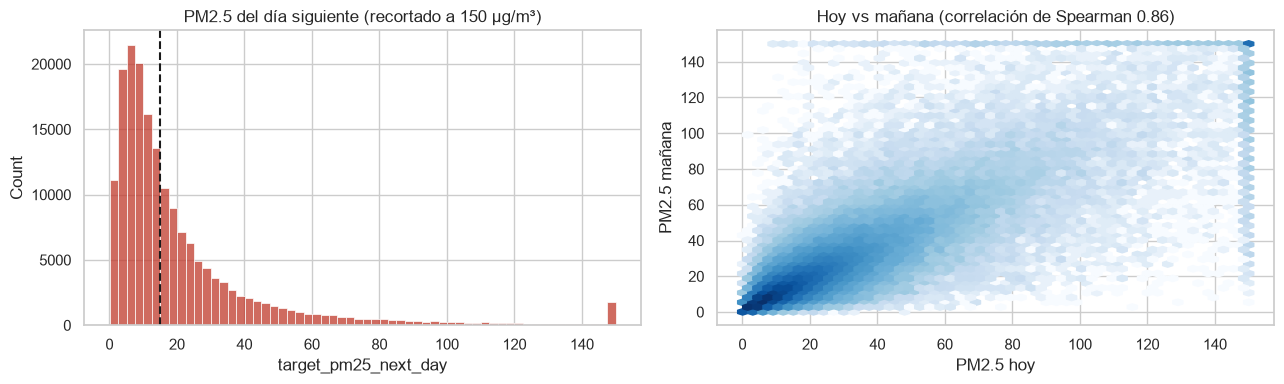

In [4]:
conocido = df[df[TARGET].notna() & df["pm2_5"].notna()]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(conocido[TARGET].clip(upper=150), bins=60, ax=ejes[0], color="#c0392b")
ejes[0].axvline(UMBRAL, ls="--", color="k")
ejes[0].set_title("PM2.5 del día siguiente (recortado a 150 µg/m³)")
ejes[1].hexbin(conocido["pm2_5"].clip(upper=150), conocido[TARGET].clip(upper=150), gridsize=50, bins="log", cmap="Blues")
ejes[1].set_xlabel("PM2.5 hoy"); ejes[1].set_ylabel("PM2.5 mañana")
ejes[1].set_title(f"Hoy vs mañana (correlación de Spearman {conocido['pm2_5'].rank().corr(conocido[TARGET].rank()):.2f})")
fig.tight_layout(); plt.show()

## 3. División por fecha y ausencia de fuga de datos
- **Entrenamiento con lo antiguo y prueba con lo reciente** (últimos 90 días): así se evalúa como se usaría en la práctica, prediciendo el futuro. Una división aleatoria mezclaría días vecinos y daría una métrica optimista.
- El entrenamiento termina **un día antes** del inicio de la prueba, porque el objetivo de una fila es el día siguiente.
- Los rezagos y la media móvil de 7 días solo usan días anteriores (no incluyen el día actual ni el objetivo).
- El objetivo no está entre las variables de entrada ni se publica en los eventos de Kafka.

In [5]:
entrenamiento, prueba = dividir_por_fecha(df, CFG["ml"]["test_days"])
print(f"entrenamiento: {len(entrenamiento):,} filas, del {entrenamiento['feature_date'].min().date()} al {entrenamiento['feature_date'].max().date()}")
print(f"prueba:        {len(prueba):,} filas, del {prueba['feature_date'].min().date()} al {prueba['feature_date'].max().date()}")
assert TARGET not in FEATURES
assert entrenamiento["feature_date"].max() + pd.Timedelta(days=1) < prueba["feature_date"].min()
print("sin traslape entre entrenamiento y prueba: OK")

entrenamiento: 158,064 filas, del 2024-05-16 al 2026-08-18
prueba:        21,753 filas, del 2026-08-20 al 2026-11-17
sin traslape entre entrenamiento y prueba: OK


## 4. Preprocesamiento y modelo
| Tipo de variable | Tratamiento |
|---|---|
| Numéricas (clima, contaminantes, rezagos, medias móviles, indicadores del país) | pasan tal cual; los nulos los maneja el modelo de forma nativa |
| Categórica (iso3, el país) | codificación ordinal; un país nunca visto recibe -1 y no rompe la inferencia |

**Qué se predice.** Como el aire de mañana se parece mucho al de hoy, el modelo no predice el nivel sino el **cambio diario**
(PM2.5 de mañana - PM2.5 de hoy) y se lo suma al valor de hoy. Así solo tiene que aportar la corrección.

**Modelo.** Promedio de dos HistGradientBoostingRegressor: uno con pérdida de **error absoluto** (robusto a los picos por tormentas de polvo) y otro con pérdida
**cuadrática** (penaliza los errores grandes, que son los que importan para las alertas). La clase ModeloCambioDiario (src/ml_model.py) incluye su propio preprocesamiento,
por lo que es **un solo objeto serializable**: el consumidor de Kafka aplica exactamente el mismo ajuste a cada mensaje y nunca reentrena.

**Regla de alerta.** Se alerta cuando el PM2.5 previsto supera **13 µg/m³**, un margen de precaución bajo la guía de la OMS (15). Una alerta perdida cuesta más que una falsa alarma.
La comparación con las líneas base usa la misma regla, para que sea justa.

In [6]:
pipeline = construir_pipeline()
pipeline.fit(entrenamiento[FEATURES], entrenamiento[TARGET])
pipeline

,columna_hoy,'pm2_5'
,semilla,42
Name,Type,Value
regresores_,list,"[Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))])]"


## 5. Evaluación en el periodo de prueba

In [7]:
previsto = pipeline.predict(prueba[FEATURES])
resultados = pd.DataFrame({
    "modelo": metricas(prueba[TARGET], previsto, UMBRAL, MARGEN),
    "línea base: mañana = hoy": metricas(prueba[TARGET], prueba["pm2_5"].to_numpy(), UMBRAL, MARGEN),
    "línea base: media de 7 días": metricas(prueba[TARGET], prueba["pm25_mean_7d"].fillna(prueba["pm2_5"]).to_numpy(), UMBRAL, MARGEN),
}).T
resultados

,mae,rmse,r2,alerta_precision,alerta_recall,alerta_f1
modelo,4.089,8.372,0.8047,0.7610,0.8845,0.8181
línea base: mañana = hoy,4.389,9.213,0.7634,0.7378,0.8854,0.8049
línea base: media de 7 días,5.526,10.711,0.6803,0.6878,0.8225,0.7492


El error absoluto medio baja 7 % frente a 'mañana = hoy'.


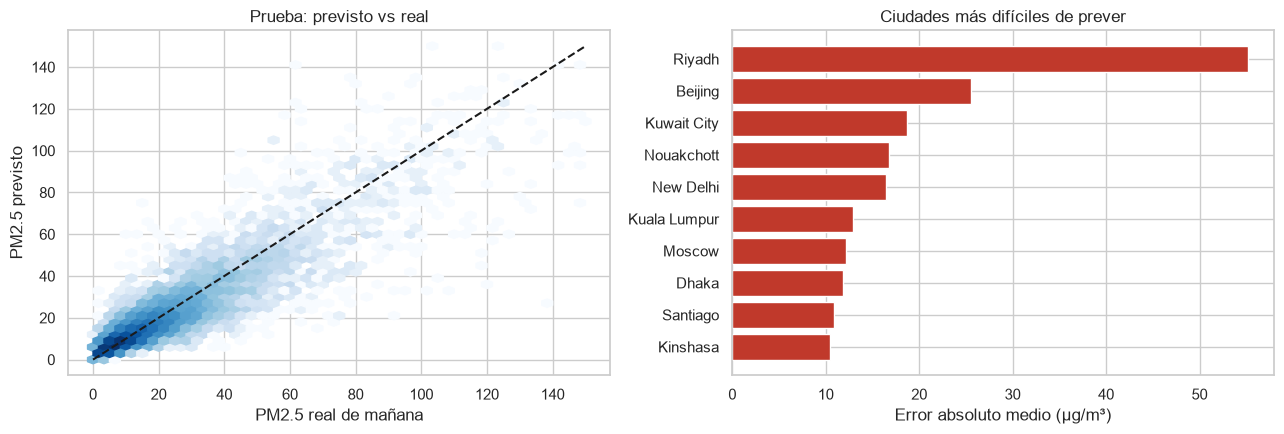

In [8]:
mejora = 100 * (1 - resultados.loc["modelo", "mae"] / resultados.loc["línea base: mañana = hoy", "mae"])
print(f"El error absoluto medio baja {mejora:.0f} % frente a 'mañana = hoy'.")
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].hexbin(prueba[TARGET], previsto, gridsize=45, bins="log", mincnt=1, cmap="Blues", extent=(0, 150, 0, 150))
ejes[0].plot([0, 150], [0, 150], ls="--", color="k")
ejes[0].set_xlabel("PM2.5 real de mañana"); ejes[0].set_ylabel("PM2.5 previsto"); ejes[0].set_title("Prueba: previsto vs real")
error = pd.Series(np.abs(prueba[TARGET].to_numpy() - previsto), index=prueba.index)
peor = error.groupby(prueba["location_name"]).mean().nlargest(10).sort_values()
ejes[1].barh(peor.index, peor.values, color="#c0392b")
ejes[1].set_xlabel("Error absoluto medio (µg/m³)"); ejes[1].set_title("Ciudades más difíciles de prever")
fig.tight_layout(); plt.show()

**Lectura.** La mejora frente a "mañana = hoy" es real pero moderada: esa regla trivial ya es muy buena porque el PM2.5 cambia poco de un día a otro. El modelo aporta sobre todo al reducir los errores grandes (RMSE) y al mejorar la precisión de la alerta sin perder recall.
Las ciudades con tormentas de polvo (por ejemplo, Riad) tienen series con picos bruscos y concentran el error.

## 6. Qué variables pesan
Importancia por permutación sobre el periodo de prueba: cuánto empeora el error al barajar una variable.

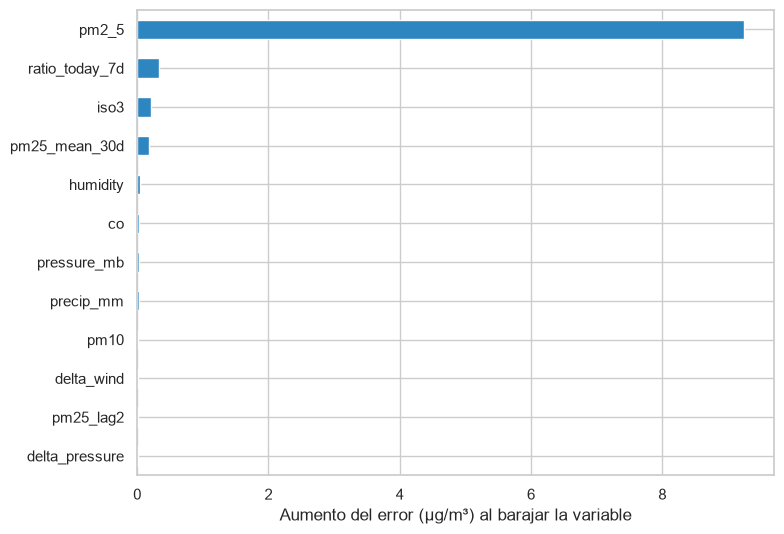

In [9]:
muestra = prueba.sample(min(6000, len(prueba)), random_state=0)
imp = permutation_importance(pipeline, muestra[FEATURES], muestra[TARGET], scoring="neg_mean_absolute_error", n_repeats=4, random_state=0)
importancia = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
importancia.head(12).sort_values().plot.barh(ax=ax, color="#2e86c1")
ax.set_xlabel("Aumento del error (µg/m³) al barajar la variable")
fig.tight_layout(); plt.show()

## 7. Limitaciones
- **Horizonte de un día.** No se evalúa más allá de t+1.
- **Datos de dos fuentes con naturaleza distinta.** El CSV trae una lectura puntual por día y la API un promedio diario; el modelo no distingue la fuente.
- **Picos por polvo y episodios extremos.** Son poco frecuentes y el modelo los subestima.
- **Indicadores del país estáticos.** Son una foto del último año disponible, no varían en el tiempo, por lo que aportan poco a la predicción diaria.
- **Sin pronóstico meteorológico del día siguiente.** Solo se conoce el clima de hoy; incorporar el pronóstico de la API mejoraría el modelo.
- **Deriva.** Si cambian las fuentes o las condiciones, el modelo debe reentrenarse (`docker compose run --rm trainer`).

## 8. Artefactos serializados
El pipeline completo y sus metadatos se guardan con `docker compose run --rm trainer` (script `src/train_model.py`, misma lógica que este cuaderno).
El consumidor de Kafka los carga **una sola vez** al iniciar y no reentrena.

In [10]:
meta = json.loads(resolve(CFG["ml"]["metadata_path"]).read_text(encoding="utf-8"))
print("archivo del modelo:", CFG["ml"]["model_path"])
print({k: meta[k] for k in ["version", "modelo", "objetivo", "sklearn", "entrenamiento_desde", "entrenamiento_hasta", "prueba_desde", "prueba_hasta"]})
pd.DataFrame(meta["metricas"]).T

archivo del modelo: models/pm25_next_day_model.pkl
{'version': 'cambio_diario_hgb_ensamble-20261118', 'modelo': 'cambio_diario_hgb_ensamble', 'objetivo': 'target_pm25_next_day', 'sklearn': '1.9.1', 'entrenamiento_desde': '2024-05-16', 'entrenamiento_hasta': '2026-08-18', 'prueba_desde': '2026-08-20', 'prueba_hasta': '2026-11-17'}


,mae,rmse,r2,alerta_precision,alerta_recall,alerta_f1
modelo,4.088,8.373,0.8046,0.7594,0.8848,0.8173
linea_base_persistencia,4.389,9.213,0.7634,0.7378,0.8854,0.8049
linea_base_media_7d,5.526,10.711,0.6803,0.6878,0.8225,0.7492
